# Reddit Bot Detection Using Graph-Based Anomaly Detection

This notebook explores unsupervised methods for identifying potentially automated Reddit accounts using behavioral features and graph representation learning.

Using Reddit comment data from May 2015, we construct a user interaction graph, extract behavioral and structural features, and apply Isolation Forest to identify anomalous users. We also train a Deep Graph Infomax (DGI) model to learn graph embeddings and compare anomaly rankings across different feature representations.

The analysis follows these steps:
1. Load and preprocess Reddit comment data.
2. Construct the user interaction graph and engineer features.
3. Examine feature distributions and correlations.
4. Compare original and transformed feature representations.
5. Train DGI models and apply Isolation Forest.
6. Analyze anomaly rankings and export results for visualization.

The original comment dataset is not included in this repository. Saved notebook outputs are retained from the original experiments.


## Import Libraries and Modules

Import the required libraries and the custom Python modules used throughout the pipeline.


In [1]:
%load_ext autoreload
%autoreload 2

In [3]:
import numpy as np
import pandas as pd
import torch
from pathlib import Path
import networkx as nx
from pathlib import Path

from src.feature_engineering import create_all_features
from src.network_creation import build_edge_df, build_pyg_graph
from src.dgi import DGI
from src.data_loader import load_subreddit_data
from src.isolation_forest import IF_Detector, run_iso_forest, combine_scores

from sklearn.preprocessing import StandardScaler

import seaborn as sns
import matplotlib.pyplot as plt



## Reproducibility

Set a random seed to improve the consistency of results across runs. The seed is used in feature engineering and model training, although complete reproducibility may still depend on the software environment and underlying libraries.


In [4]:
SEED = 587156
np.random.seed(SEED)

## Data Loading

The project uses Reddit comments from May 2015, previously extracted and organized by subreddit.

The `load_subreddit_data()` function loads the cached comment data. Setting `ALL_SUBS = True` includes all available subreddits, while setting it to `False` allows a subset to be selected using `subreddits.txt`.

The original analysis loaded approximately 24.4 million comments across 82 subreddits.

Deleted accounts and AutoModerator are excluded before feature engineering to avoid treating them as ordinary users.

The configuration parameters also control graph construction, minimum user activity, and model training.


In [5]:
# will load all subs if true, else loads from subreddits.txt
ALL_SUBS = True

# paths
PROJECT_ROOT = Path.cwd().resolve()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA_PATH = str(PROJECT_ROOT / "data")
OUT_DIR = str(PROJECT_ROOT / "results")

### Parameters
# minimum connections to keep an edge between users
MIN_WEIGHT = 5
# only use posts with fewer comments
MAX_AUTHORS = 30
# keep authors with at least this many comments
MIN_COMMENTS = 5

## DGI
HIDDEN_DIM = 50
EPOCHS = 50
LEARNING_RATE = 0.001

## Isolation Forest
N_ESIMATORS = 100
CONTAMINATION = 'auto'

# How many anomalous users to use for the visualization
TOP_N = 500


In [7]:
if ALL_SUBS:
    subreddits = None
else:
    with open("../subreddits.txt", "r") as f:
        subreddits = [line.strip() for line in f if line.strip()]

data = load_subreddit_data(subreddits, path=DATA_PATH,
                            # reload=True, load=True
                            )


Loading cached data for 2007scape...
Loading cached data for AdviceAnimals...
Loading cached data for amiibo...
Loading cached data for Android...
Loading cached data for anime...
Loading cached data for AskMen...
Loading cached data for AskReddit...
Loading cached data for AskWomen...
Loading cached data for asoiaf...
Loading cached data for atheism...
Loading cached data for aww...
Loading cached data for baseball...
Loading cached data for Bitcoin...
Loading cached data for buildapc...
Loading cached data for CasualConversation...
Loading cached data for CFB...
Loading cached data for Christianity...
Loading cached data for csgobetting...
Loading cached data for DestinyTheGame...
Loading cached data for DotA2...
Loading cached data for electronic_cigarette...
Loading cached data for europe...
Loading cached data for explainlikeimfive...
Loading cached data for fatpeoplehate...
Loading cached data for ffxiv...
Loading cached data for Fireteams...
Loading cached data for Fitness...
Lo

In [8]:
# filtering bad users to avoid requerying data

data = data[~data["author"].isin(["[deleted]", "AutoModerator"])]
# data.head()

## Feature Selection

We extract features describing different aspects of user behavior and interactions. These are divided into four categories:

- **Graph features:** Degree, weighted degree, clustering coefficient, PageRank, and betweenness centrality.
- **Temporal features:** Posting activity across hours and days, active days, and time between comments.
- **Content features:** Text similarity, comment length statistics, URL frequency, and capitalization patterns.
- **Metadata features:** Comment counts, comment scores, username patterns, flair, and gilded counts.

The `features_to_keep` dictionary controls which features are included in the analysis.


In [9]:
features_to_keep = {
    "author": True,

    # Graph features
    "degree": True,
    "weighted_degree": True,
    "clustering": True,
    "pagerank": True,
    "betweenness": True,

    # Temporal features
    "hour_spread": True,
    "dow_variance": True,
    "active_days_ratio": True,
    "mean_hours_between": True,
    "std_hours_between": True,

    # Content features
    "text_similarity": True,
    "avg_comment_length": True,
    "comment_length_variance": True,
    "url_ratio": True,
    "no_caps_ratio": True,

    # metadata features
    "comment_count": True,
    "avg_score": True,
    "score_variance": True,
    "suspicious_username": True,
    "has_flair": True,
    "gilded_count": True,
}

feature_columns = [col for col, keep in features_to_keep.items() if keep]

## Feature Engineering and Graph Construction

A weighted user interaction graph is constructed by connecting accounts that commented on the same posts. Edge weights represent the frequency of these shared interactions.

To reduce the size and complexity of the graph, we apply the following filters:

- `MIN_WEIGHT`: Minimum edge weight required to retain a connection.
- `MAX_AUTHORS`: Maximum number of authors permitted on a post when constructing edges.
- `MIN_COMMENTS`: Minimum number of comments required for a user to be included in feature engineering.

The `create_all_features()` function computes the selected graph, temporal, content, and metadata features and returns a user feature dataframe and NetworkX graph.

This step is computationally expensive, so the processed results are saved for reuse.


In [10]:
# adjust the parameters so the edge data is not too big
edges = build_edge_df(data, min_weight=MIN_WEIGHT, max_authors=MAX_AUTHORS)
print("number of edges:", len(edges))

number of edges: 135503


In [11]:
features, G = create_all_features(
    data_df=data,
    edge_df=edges,
    features=feature_columns,
    min_comments=MIN_COMMENTS,
    seed=SEED
    )

Building NetworkX graph...
--Graph built
Computing graph features...
--degree completed
--weighted_degree completed
--clustering completed
--pagerank completed
--betweenness completed
Computing temporal features...
Computing content features...
Computing metadata features...
Combining all features...


## Save Processed Data

Save the outputs of feature engineering and graph construction:

- `features.parquet`: Engineered features for each user.
- `edges.parquet`: Weighted connections between users.
- `graph.graphml`: NetworkX representation of the user interaction graph.

These files allow subsequent analysis to use the previously computed results without repeating the entire data processing pipeline.


In [16]:
features.to_parquet(OUT_DIR + "/features.parquet")
edges.to_parquet(OUT_DIR + "/edges.parquet")
nx.write_graphml(G, OUT_DIR + "/graph.graphml")


## Load Precomputed Features and Graph

Load the saved feature dataframe, edge dataframe, and NetworkX graph.

The following experiments use these precomputed results. This separates the relatively expensive feature engineering process from the model development and analysis.


In [21]:
features = pd.read_parquet(OUT_DIR + "/features.parquet")
edges_df = pd.read_parquet(OUT_DIR + "/edges.parquet")
G = nx.read_graphml(OUT_DIR + "/graph.graphml")
feature_df = features[feature_columns]

## Feature Distribution Analysis

Before training the models, we examine the distributions of the engineered features using summary statistics, skewness, and kurtosis.

Several features exhibit substantial right skew, particularly graph measures such as degree, weighted degree, PageRank, and betweenness centrality, as well as comment-length and score variance.

Many users also have zero values for graph features, indicating that they have few or no connections in the filtered interaction graph.

These characteristics motivate an experiment with log transformations to determine whether reducing the influence of extreme values changes the anomalies identified by the models.


In [22]:
feature_columns = [c for c in features.columns if c != "author"]

summary = features[feature_columns].describe().T
summary['skew'] = features[feature_columns].skew()
summary['kurtosis'] = features[feature_columns].kurtosis()

summary

,count,mean,std,min,25%,50%,75%,max,skew,kurtosis
degree,632277.0,0.428619,6.786275,0.000000,0.000000,0.000000,0.000000,1.612000e+03,62.073681,8603.956545
weighted_degree,632277.0,3.556732,76.824973,0.000000,0.000000,0.000000,0.000000,1.852500e+04,99.107310,17154.550993
clustering,632277.0,0.003521,0.054266,0.000000,0.000000,0.000000,0.000000,1.000000e+00,16.384578,276.312075
pagerank,632277.0,0.000002,0.000039,0.000000,0.000000,0.000000,0.000000,1.356807e-02,144.064556,37326.776562
betweenness,632277.0,0.000006,0.000428,0.000000,0.000000,0.000000,0.000000,1.608166e-01,264.098752,86144.289874
hour_spread,632277.0,0.371685,0.209079,0.041667,0.208333,0.291667,0.500000,1.000000e+00,0.863663,-0.065963
dow_variance,632277.0,42.370574,535.266599,0.000000,1.000000,3.600000,13.619048,1.470277e+05,135.219493,28798.589492
active_days_ratio,632277.0,0.442815,0.237547,0.064516,0.259259,0.379310,0.576923,1.000000e+00,0.884220,-0.091769
mean_hours_between,632277.0,43.888540,36.748847,0.000000,15.033597,33.879286,63.637727,1.858753e+02,1.125153,0.818401
std_hours_between,632277.0,56.187089,42.267130,0.000000,25.201730,46.834163,76.616259,3.171566e+02,1.337608,2.335657


## Feature Correlation Analysis

We examine correlations between numerical features to identify potential redundancy.

Degree and weighted degree are highly correlated (approximately 0.956). Although Isolation Forest can handle correlated features, including both may give similar aspects of network connectivity additional influence.

For the preprocessing comparison, we retain degree and remove weighted degree, as degree provides a simpler measure of network connectivity.


degree                   weighted_degree            0.955562
weighted_degree          degree                     0.955562
mean_hours_between       std_hours_between          0.835011
std_hours_between        mean_hours_between         0.835011
score_variance           avg_score                  0.824536
avg_score                score_variance             0.824536
active_days_ratio        std_hours_between          0.798728
std_hours_between        active_days_ratio          0.798728
mean_hours_between       active_days_ratio          0.746060
active_days_ratio        mean_hours_between         0.746060
pagerank                 degree                     0.701260
degree                   pagerank                   0.701260
pagerank                 weighted_degree            0.673610
weighted_degree          pagerank                   0.673610
avg_comment_length       comment_length_variance    0.632537
comment_length_variance  avg_comment_length         0.632537
betweenness             

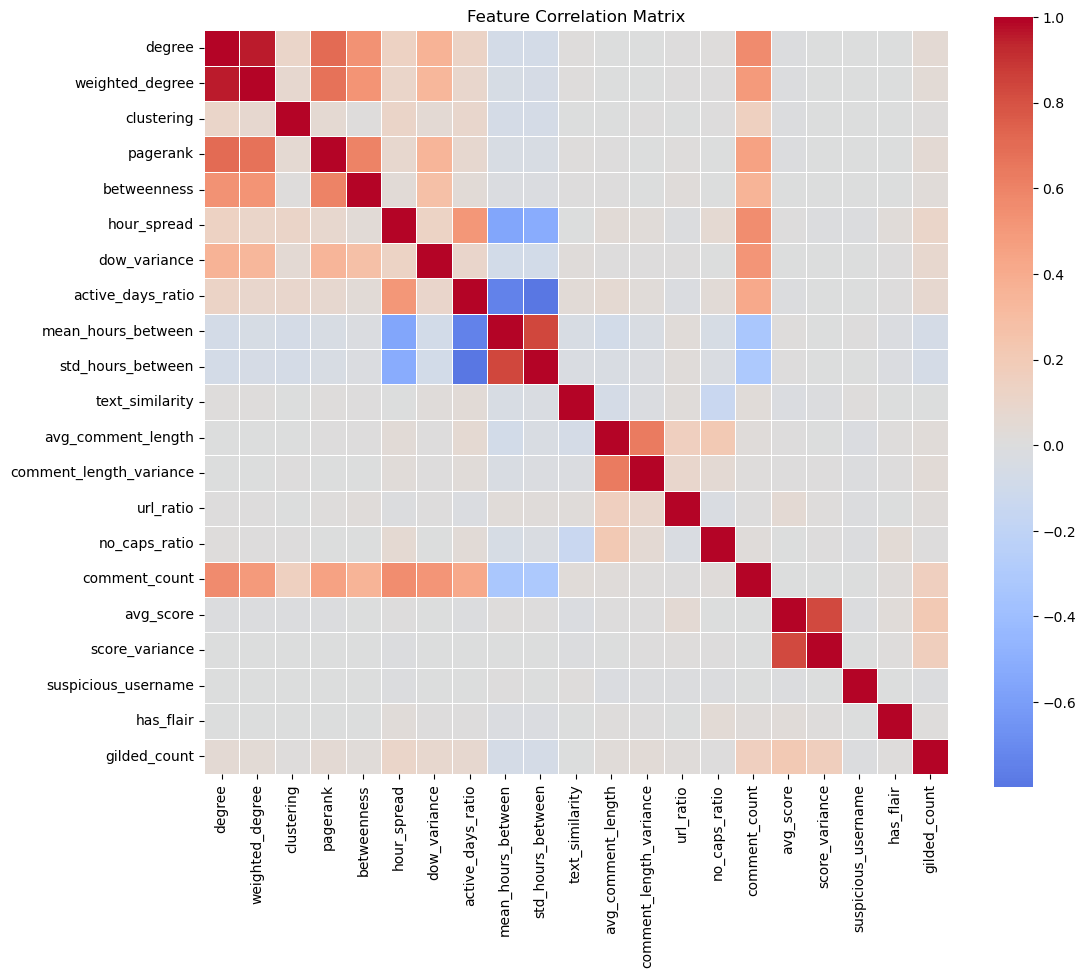

In [23]:
# numeric features
numeric_cols = feature_df.select_dtypes(include=[np.number]).columns

# correlation matrix
corr = feature_df[numeric_cols].corr()

# highest correlations
high_corr = corr.abs().unstack().sort_values(ascending=False)
high_corr = high_corr[high_corr < 1]  # remove self-correlation
print(high_corr.head(21))

plt.figure(figsize=(12,10))
sns.heatmap(corr, cmap="coolwarm", center=0, square=True, linewidths=.5)
plt.title("Feature Correlation Matrix")
plt.show()

## Log Transformation Experiment

We compare the original numerical features against a modified representation designed to reduce skewness and redundancy.

The modified representation applies a `log1p` transformation to selected heavily skewed features:

- Degree
- PageRank
- Betweenness centrality
- Comment-length variance
- Score variance

Weighted degree is also removed because of its high correlation with degree.

The goal is to investigate whether reducing the magnitude of extreme values produces more informative anomaly rankings or instead suppresses unusual behavior that may be useful for detecting automated accounts.


In [24]:
# Apply a log1p transform to heavily skewed features.
skewed_features = [
    "degree",
    "pagerank",
    "betweenness",
    "comment_length_variance",
    "score_variance"
]

features_log = feature_df.copy()

for f in skewed_features:
    if f in features_log.columns:
        features_log[f] = np.log1p(features_log[f])

# Drop weighted_degree
if "weighted_degree" in features_log.columns:
    features_log = features_log.drop(columns=["weighted_degree"])

# Examine transformed features
# print(features_log[skewed_features].head(20))


## Feature Standardization

The numerical features are standardized using `StandardScaler` before being used in DGI and Isolation Forest.

We prepare two representations:

- **Original features:** Standardized numerical values without log transformation.
- **Transformed features:** Log-transformed values for selected skewed features, followed by standardization.

Both representations exclude weighted degree to maintain the same feature columns.

The scaler is fitted on the original numerical features and then applied to the transformed representation, allowing both to use the same scaling parameters.

These representations are compared in the following experiments.


In [26]:
numeric_cols_log = features_log.select_dtypes(include=[np.number]).columns

scaler = StandardScaler()

# Original features
feature_df_scaled = feature_df[numeric_cols_log].copy()
feature_df_scaled[numeric_cols_log] = scaler.fit_transform(feature_df_scaled[numeric_cols_log])

# Log-transformed features
features_log_scaled = features_log.copy()
features_log_scaled[numeric_cols_log] = scaler.transform(features_log_scaled[numeric_cols_log])


## Deep Graph Infomax (DGI)

Deep Graph Infomax is an unsupervised graph representation learning method that uses a graph neural network to learn node embeddings.

We convert the Reddit interaction graph and user features into PyTorch Geometric data objects. A DGI model is then trained to generate embeddings that incorporate graph structure and user feature information.

Two models are trained:

- **Original features:** DGI trained using the standardized original features.
- **Transformed features:** DGI trained using the standardized, log-transformed features.

The resulting embeddings are used as an alternative representation of users for anomaly detection.

This allows us to investigate whether graph representation learning captures anomalous behavior that is not apparent from engineered features alone.


In [27]:
# Add author column back
feature_df_scaled['author'] = features['author'].values
features_log_scaled['author'] = features['author'].values

# Original Features
pyg = build_pyg_graph(edge_df=edges_df, feature_df=feature_df_scaled)

# Modified Features
pyg_mod = build_pyg_graph(edge_df=edges_df, feature_df=features_log_scaled)


Graph created: 22,866 nodes, 135,503 edges
Graph created: 22,866 nodes, 135,503 edges


In [28]:
# Original Features
dgi = DGI(data=pyg, hidden=HIDDEN_DIM, learning_rate=LEARNING_RATE, epochs=EPOCHS, seed=SEED)
embedding = dgi.embed()

# Modified Features
dgi_mod = DGI(data=pyg_mod, hidden=HIDDEN_DIM, learning_rate=LEARNING_RATE, epochs=EPOCHS, seed=SEED)
embedding_mod = dgi_mod.embed()  # fixed: previously was dgi.embed()


Epoch 0, Loss: 1.3884
Epoch 20, Loss: 1.2025
Epoch 40, Loss: 1.1685
Epoch 0, Loss: 1.5600
Epoch 20, Loss: 1.2176
Epoch 40, Loss: 1.1750


## Isolation Forest Anomaly Detection

Isolation Forest is applied to identify users with unusual feature representations.

We compare three approaches:

1. **Engineered features:** Isolation Forest applied directly to the standardized user features.
2. **DGI embeddings:** Isolation Forest applied to embeddings learned by the graph model.
3. **Combined scores:** Anomaly scores from the engineered features and DGI embeddings are combined to produce an additional ranking.

Each approach generates a ranking of potentially anomalous users.

We repeat these comparisons using the transformed feature representation to evaluate the effect of preprocessing on the resulting rankings.

The highest-ranked accounts from each approach are displayed for qualitative comparison.

Because confirmed bot labels are unavailable, these rankings are interpreted as potential anomalies rather than verified bot classifications.


In [29]:
# Original Features
scores_from_features = run_iso_forest(X=feature_df_scaled, index='author', seed=SEED)
scores_from_embedding = run_iso_forest(X=embedding, index='author', seed=SEED)
scores = combine_scores(scores_from_features, scores_from_embedding)

print("Top 10 anomalies (features):")
print(scores_from_features.head(10))

print("\n\nTop 10 anomalies (DGI):")
print(scores_from_embedding.head(10))

print("\n\nTop 10 anomalies (combined):")
print(scores.head(10))


Top 10 anomalies (features):
                     author  anomaly_score
177437       MTGCardFetcher       0.297125
308690  TweetsInCommentsBot       0.295686
119193        GustavoFrings       0.290704
605036          ttumblrbots       0.283792
193486             Moskau50       0.282395
86696    DumbCollegeStudent       0.279350
452077     imgurtranscriber       0.278892
315155             VerseBot       0.278215
443894            hoosakiwi       0.277411
352292          autowikibot       0.276723


Top 10 anomalies (DGI):
                author  anomaly_score
714            Andarel       0.277457
17442       lead_salad       0.263816
8324      PopcornMouse       0.260473
13414        br0ckster       0.259988
17997        mea852456       0.259217
18247          mnik224       0.258355
4625          Highfire       0.248536
22195   walkonthebeach       0.247660
396    ASOIAFSearchBot       0.242956
21464      themanycids       0.241772


Top 10 anomalies (combined):
                    aut

In [30]:
# Modified Features
scores_from_features_log = run_iso_forest(X=features_log_scaled, index='author', seed=SEED)
scores_from_embedding_log = run_iso_forest(X=embedding_mod, index='author', seed=SEED)
scores_log = combine_scores(scores_from_features_log, scores_from_embedding_log)

print("Top 10 anomalies (features, log-transformed):")
print(scores_from_features_log.head(10))

print("\n\nTop 10 anomalies (DGI, log-transformed):")
print(scores_from_embedding_log.head(10))

print("\n\nTop 10 anomalies (combined, log-transformed):")
print(scores_log.head(10))

Top 10 anomalies (features, log-transformed):
                     author  anomaly_score
308690  TweetsInCommentsBot       0.294051
119193        GustavoFrings       0.287831
177437       MTGCardFetcher       0.286517
193486             Moskau50       0.286272
605036          ttumblrbots       0.280429
86696    DumbCollegeStudent       0.278962
2418      12_Years_A_Toucan       0.274580
452077     imgurtranscriber       0.273927
352284             autotldr       0.272469
609239             urban287       0.272120


Top 10 anomalies (DGI, log-transformed):
                  author  anomaly_score
21387  thebeastandhisdoe       0.258544
18076            mfstyrf       0.257510
8660     RamsesThePigeon       0.256245
18266             mokeru       0.255769
21420        thedude0121       0.254933
8776      Reddit_Amiibro       0.242602
20612        sissyboi333       0.241479
9333    SecondSonOfDavid       0.239419
9594     SilverDeoxys563       0.236744
1320              BigRLC       0.23603

## Export Results for Visualization

The final step exports the anomaly rankings and user interaction data to JSON for an interactive D3.js visualization.

The export selects the top 500 users according to the combined anomaly scores from the original-feature and DGI models, along with the relevant graph connections and user features.

The resulting `graph.json` file is used by the visualization to explore relationships between potentially anomalous accounts across subreddits.

Although the engineered-feature model produced the most interpretable rankings during qualitative inspection, the visualization uses the combined scores to incorporate information from both approaches.

In [33]:
from src.to_json import *
generated_json = Path(
    build_graph_json(edge_df=edges_df, comments_df=data, anomaly_df=scores, features_df=feature_df, top_n=500)
)

target_json = PROJECT_ROOT / "visualization" / "graph.json"
target_json.parent.mkdir(parents=True, exist_ok=True)

if generated_json.resolve() != target_json.resolve():
    generated_json.replace(target_json)

'graph.json'

## Results and Discussion

### Engineered Features

Isolation Forest applied to the original engineered features produced the most interpretable anomaly rankings during qualitative inspection. Several highly ranked accounts exhibited unusual posting activity or interaction patterns consistent with potentially automated behavior.

### Feature Transformations

The log-transformed representation produced different anomaly rankings but did not appear to improve the identification of recognizable automated accounts.

Compressing extreme feature values may have reduced the influence of behaviors that helped distinguish some of the most unusual users.

### DGI Embeddings

DGI embeddings captured structural information from the interaction graph and identified different types of anomalies.

However, rankings based on DGI embeddings were less effective at highlighting recognizable automated behavior during manual inspection than those based on engineered features.

Combining DGI and engineered-feature scores introduced additional variation into the candidate rankings but did not demonstrate a clear improvement over the engineered-feature approach alone.

### Limitations

The primary limitation of this analysis is the lack of reliable ground-truth bot labels. Consequently, we cannot quantitatively measure detection accuracy or determine whether highly ranked accounts are actually automated.

The results are based on exploratory analysis and qualitative inspection of anomalous accounts.

### Conclusion

In these experiments, Isolation Forest using engineered behavioral features provided the clearest and most interpretable anomaly rankings. DGI offered a complementary representation of the user interaction graph but did not clearly outperform the engineered-feature approach.

These results suggest that carefully designed behavioral features can be valuable for unsupervised anomaly detection, while graph embeddings may provide additional information about unusual network structure.
